<a href="https://colab.research.google.com/github/Deviapritha/Capstone-Project/blob/main/Module%20End%20Assignment%3A%20Python%20For%20Data%20Analysis%20%E2%80%9CSocial%20Media%20Engagement%20Analytics%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv("social_media_engagement_5000.csv")

In [ ]:
df.head()


In [ ]:
df.tail()

In [ ]:
df.dtypes

In [ ]:
df.info()

In [ ]:
df["age"].isnull().sum()
df[df["age"].isnull()]

In [ ]:
df["age"] = df["age"].fillna(df["age"].median())


In [ ]:
df["age"] = df["age"].astype(int)
print(df["age"].dtype)
print(df["age"].isnull().sum())

In [ ]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [ ]:
df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')

In [ ]:
categorical_columns = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for col in categorical_columns:
    df[col] = df[col].astype('category')

In [ ]:
df['is_verified'] = df['is_verified'].astype('boolean')

In [ ]:
df.info()
df.dtypes

In [ ]:
df.isnull().sum()

In [ ]:
df['likes'] = df['likes'].fillna(df['likes'].median())

df['comments'] = df['comments'].fillna(df['comments'].median())

df['shares'] = df['shares'].fillna(df['shares'].median())
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])

df['country'] = df['country'].fillna(df['country'].mode()[0])

df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])
df['posted_at'] = df['posted_at'].ffill()

In [ ]:
df.duplicated().sum()
df[df.duplicated()]
df[df.duplicated(subset=['user_id', 'post_id'])]

In [ ]:
df.rename(columns={'old_name': 'new_name'}, inplace=True)
df.columns = df.columns.str.title()

In [ ]:
numeric_columns = [
    'age', 'likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count',
    'follower_count', 'engagement_rate'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    errors='coerce'
)

In [ ]:
df['post_type'] = (
    df['post_type']
    .astype('string')
    .str.strip()
    .str.title()
)

In [ ]:
df['country'] = (
    df['country']
    .astype('string')
    .str.strip()
    .str.upper()
)

In [ ]:
df['Is_Verfied'] = (
    df['Is_Verified']
    .astype('string')
    .str.strip()
    .str.title()
)
df['Post_Type'] = (
    df['Post_Type']
    .astype('string')
    .str.strip()
    .str.title()
)
df['Post_Category'] = (
    df['Post_Category']
    .astype('string')
    .str.strip()
    .str.title()
)


In [ ]:
df[
    (df['Likes'] < 0) |
    (df['Comments'] < 0) |
    (df['Shares'] < 0)
]

In [ ]:
df[
    (df['Age'] < 13) |
    (df['Age'] > 100)
]

In [ ]:
df[
    (df['Watch_Time_Sec'] < 0) |
    (df['Follower_Count'] < 0) |
    (df['Impression_Count'] < 0)
]

In [ ]:
df['Hashtags'] = df['Hashtags'].fillna('')
df['Hashtag_Count'] = df['Hashtags'].str.findall(r'#\w+').str.len()
df[['Hashtags', 'Hashtag_Count']].head(10)

,Hashtags,Hashtag_Count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [ ]:
df['Sentiment'].value_counts(dropna=False)

In [ ]:
df['Sentiment'] = (
    df['Sentiment']
    .astype('string')
    .str.strip()
    .str.lower()
    .str.title()
)

In [ ]:
df.duplicated().sum()

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.shape

(5000, 21)

In [ ]:
df.columns


In [ ]:
len(df.columns)

In [ ]:
df.dtypes

In [ ]:
df.info()

In [ ]:
df.isnull().sum()

In [ ]:
df.describe()

In [ ]:
df.describe(include='object')

In [ ]:
df.describe(include='all')

In [ ]:
df['Post_Type'].value_counts()

In [ ]:
df['Gender'].value_counts()

In [ ]:
df['Sentiment'].value_counts()

In [ ]:
df['Post_Type'].value_counts(normalize=True) * 100

In [ ]:
df['Post_Type'].unique()

In [ ]:
df['Country'].unique()

In [ ]:
df['Sentiment'].unique()

In [ ]:
df['Post_Type'].nunique()

4

In [ ]:
df['Country'].nunique()

10

In [ ]:
df['Sentiment'].nunique()

3

In [ ]:
numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()

correlation_matrix

In [ ]:
df.groupby('Post_Type', observed=True)['Likes'].mean()

In [ ]:
df.groupby('Country', observed=True)['Impression_Count'].sum()

In [ ]:
df.groupby('Post_Category', observed=True)['Comments'].mean()

In [ ]:
df.groupby('Device_Type', observed=True)['Shares'].mean()

In [ ]:
df.groupby('Sentiment', observed=True)['Engagement_Rate'].mean()

In [ ]:
df.groupby('Post_Type', observed=True).agg({
    'Likes': 'mean',
    'Comments': 'mean',
    'Shares': 'sum',
    'Impression_Count': 'sum',
    'Engagement_Rate': 'mean'
})

In [ ]:
df.groupby(
    ['Country', 'Post_Type'],
    observed=True
)[['Likes', 'Comments', 'Shares']].mean()

In [ ]:
df['Engagement_Score'] = (
    df['Likes'] +
    (df['Comments'] * 2) +
    (df['Shares'] * 3)
)

In [ ]:
df[['Likes', 'Comments', 'Shares', 'Engagement_Score']].head(10)

In [ ]:
df['Hashtags'] = df['Hashtags'].fillna('')

df['Hashtag_Count'] = (
    df['Hashtags']
    .str.findall(r'#\w+')
    .str.len()
)
df[['Hashtags', 'Hashtag_Count']].head(10)

In [ ]:
post_type_summary = df.groupby(
    'Post_Type',
    observed=True
).agg({
    'Likes': 'mean',
    'Comments': 'mean',
    'Shares': 'mean',
    'Engagement_Score': 'mean',
    'Impression_Count': 'sum'
})

post_type_summary

In [ ]:
post_type_summary.sort_values(
    by='Engagement_Score',
    ascending=False
)

In [ ]:
country_summary = df.groupby(
    'Country',
    observed=True
).agg({
    'Likes': 'sum',
    'Comments': 'sum',
    'Shares': 'sum',
    'Impression_Count': 'sum',
    'Engagement_Score': 'mean'
})

country_summary

In [ ]:
country_summary.sort_values(
    by='Impression_Count',
    ascending=False
)

In [ ]:
sentiment_summary = df.groupby(
    'Sentiment',
    observed=True
).agg({
    'Likes': 'mean',
    'Comments': 'mean',
    'Shares': 'mean',
    'Engagement_Score': 'mean',
    'Impression_Count': 'mean'
})

sentiment_summary

In [ ]:
df.groupby(
    ['Country', 'Post_Type'],
    observed=True
).agg({
    'Likes': 'mean',
    'Comments': 'mean',
    'Shares': 'mean',
    'Engagement_Score': 'mean'
})

In [ ]:
stats_columns = [
    'Likes',
    'Comments',
    'Shares',
    'Watch_Time_Sec',
    'Engagement_Rate',
    'Follower_Count'
]

stats_df = df[stats_columns]

print("Mean:")
print(stats_df.mean())

print("\nMedian:")
print(stats_df.median())

print("\nMode:")
print(stats_df.mode())

print("\nStandard Deviation:")
print(stats_df.std())

print("\nVariance:")
print(stats_df.var())

print("\nPercentiles:")
print(stats_df.quantile([0.25, 0.50, 0.75, 0.90]))
print("\nSkewness:")
print(stats_df.skew())

print("\nKurtosis:")
print(stats_df.kurt())

statistical_summary = pd.DataFrame({
    'Mean': stats_df.mean(),
    'Median': stats_df.median(),
    'Mode': stats_df.mode().iloc[0],
    'Std_Dev': stats_df.std(),
    'Variance': stats_df.var(),
    'Skewness': stats_df.skew(),
    'Kurtosis': stats_df.kurt()
})

print("\nFinal Statistical Summary:")
display(statistical_summary)

In [165]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')

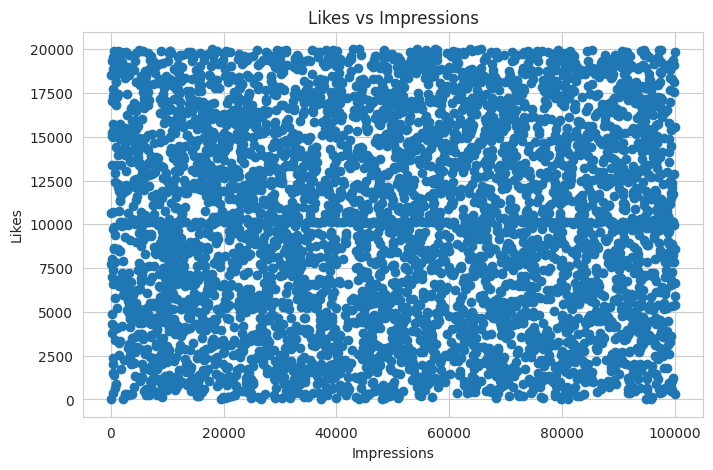

In [166]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Impression_Count'], df['Likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

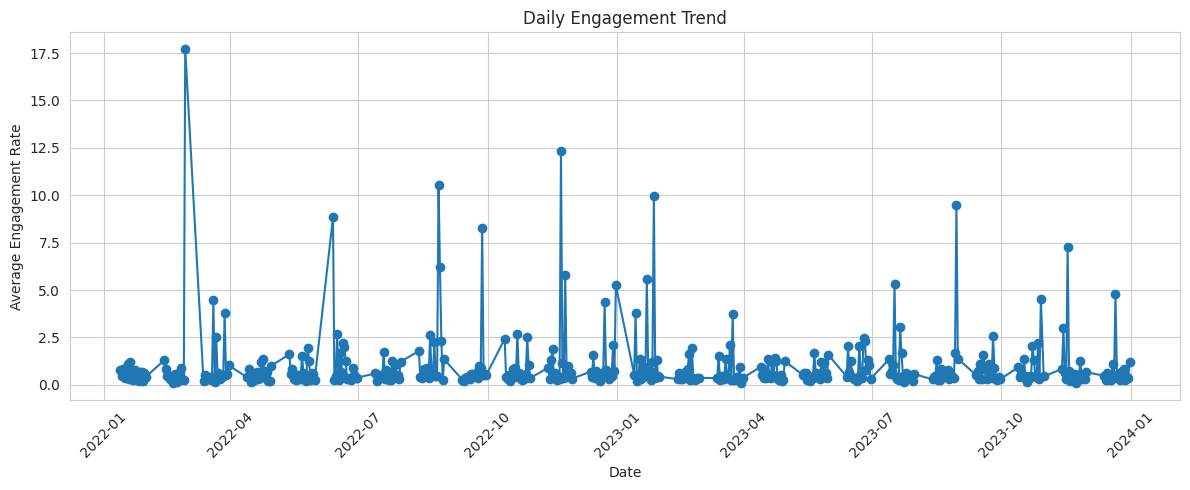

In [167]:
df['Posted_At'] = pd.to_datetime(
    df['Posted_At'],
    errors='coerce',
    dayfirst=True
)

daily_engagement = df.groupby(
    df['Posted_At'].dt.date
)['Engagement_Rate'].mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values,
         marker='o')

plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.title('Daily Engagement Trend')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

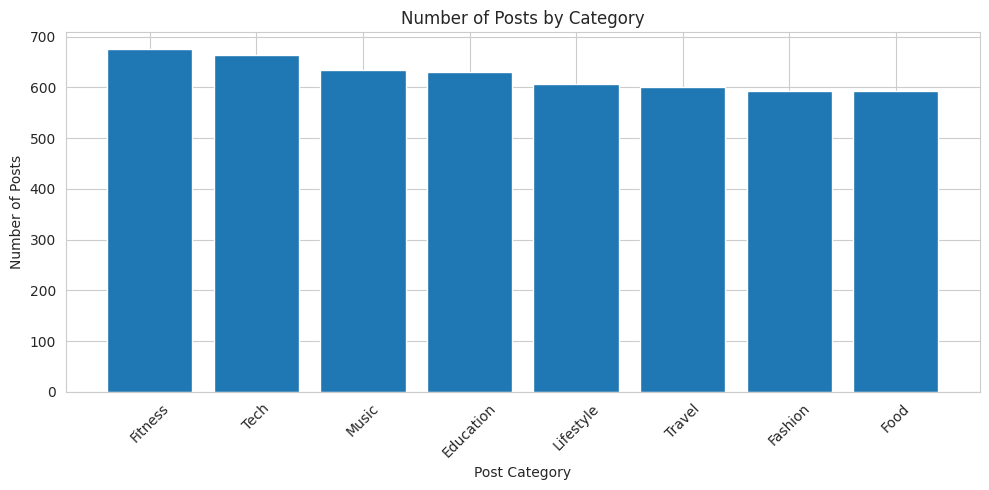

In [168]:
posts_by_category = df['Post_Category'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(posts_by_category.index, posts_by_category.values)

plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

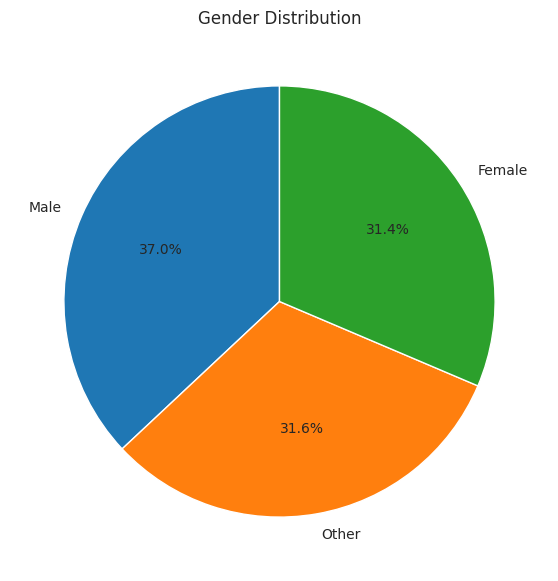

In [169]:
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.show()

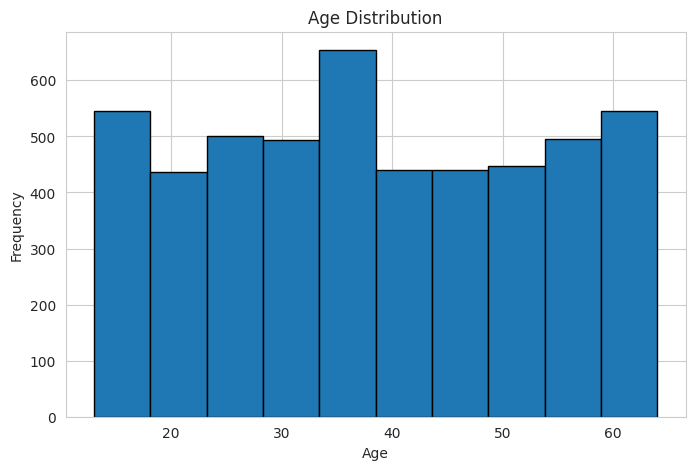

In [170]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'].dropna(), bins=10, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')

plt.show()

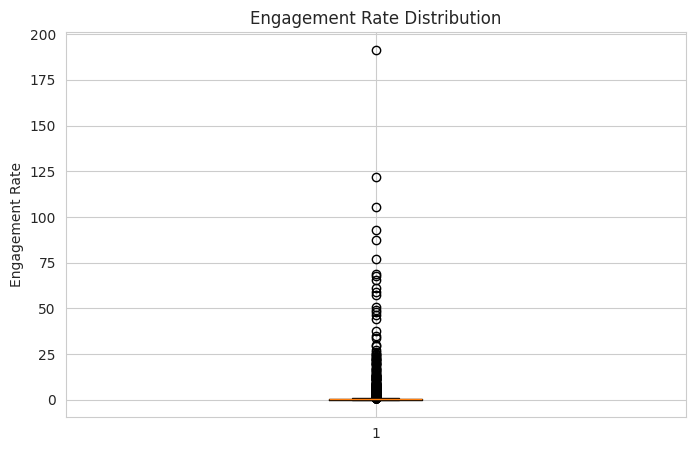

In [171]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Engagement_Rate'].dropna())

plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Distribution')

plt.show()

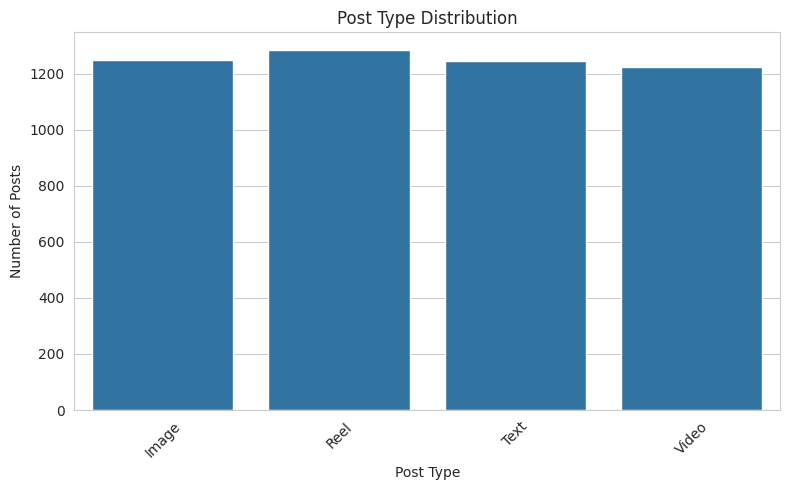

In [172]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Post_Type')

plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Post Type Distribution')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

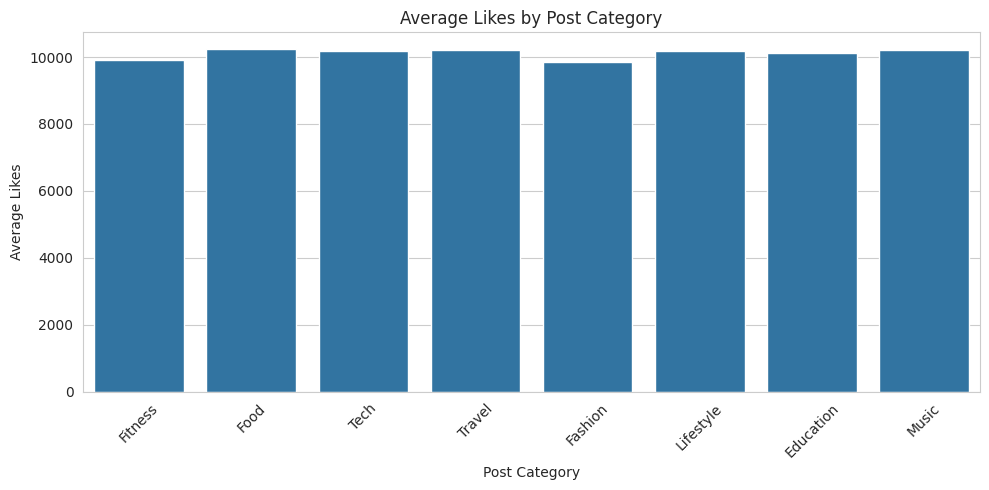

In [173]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='Post_Category',
    y='Likes',
    estimator='mean',
    errorbar=None
)

plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Post Category')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

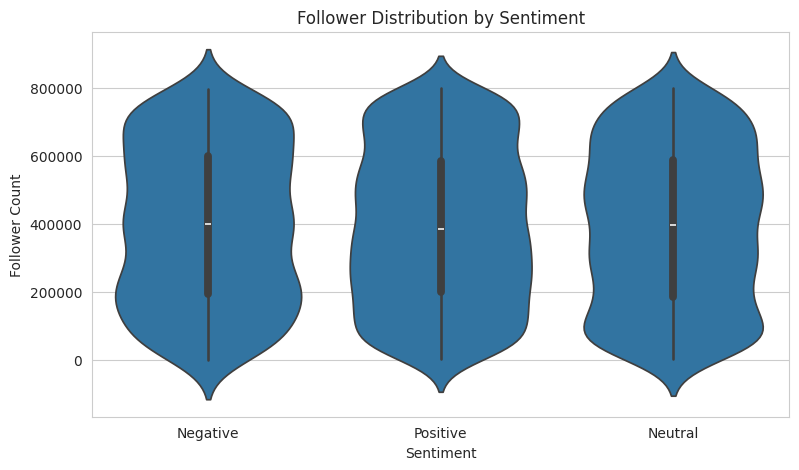

In [174]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='Sentiment',
    y='Follower_Count'
)

plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.title('Follower Distribution by Sentiment')

plt.show()

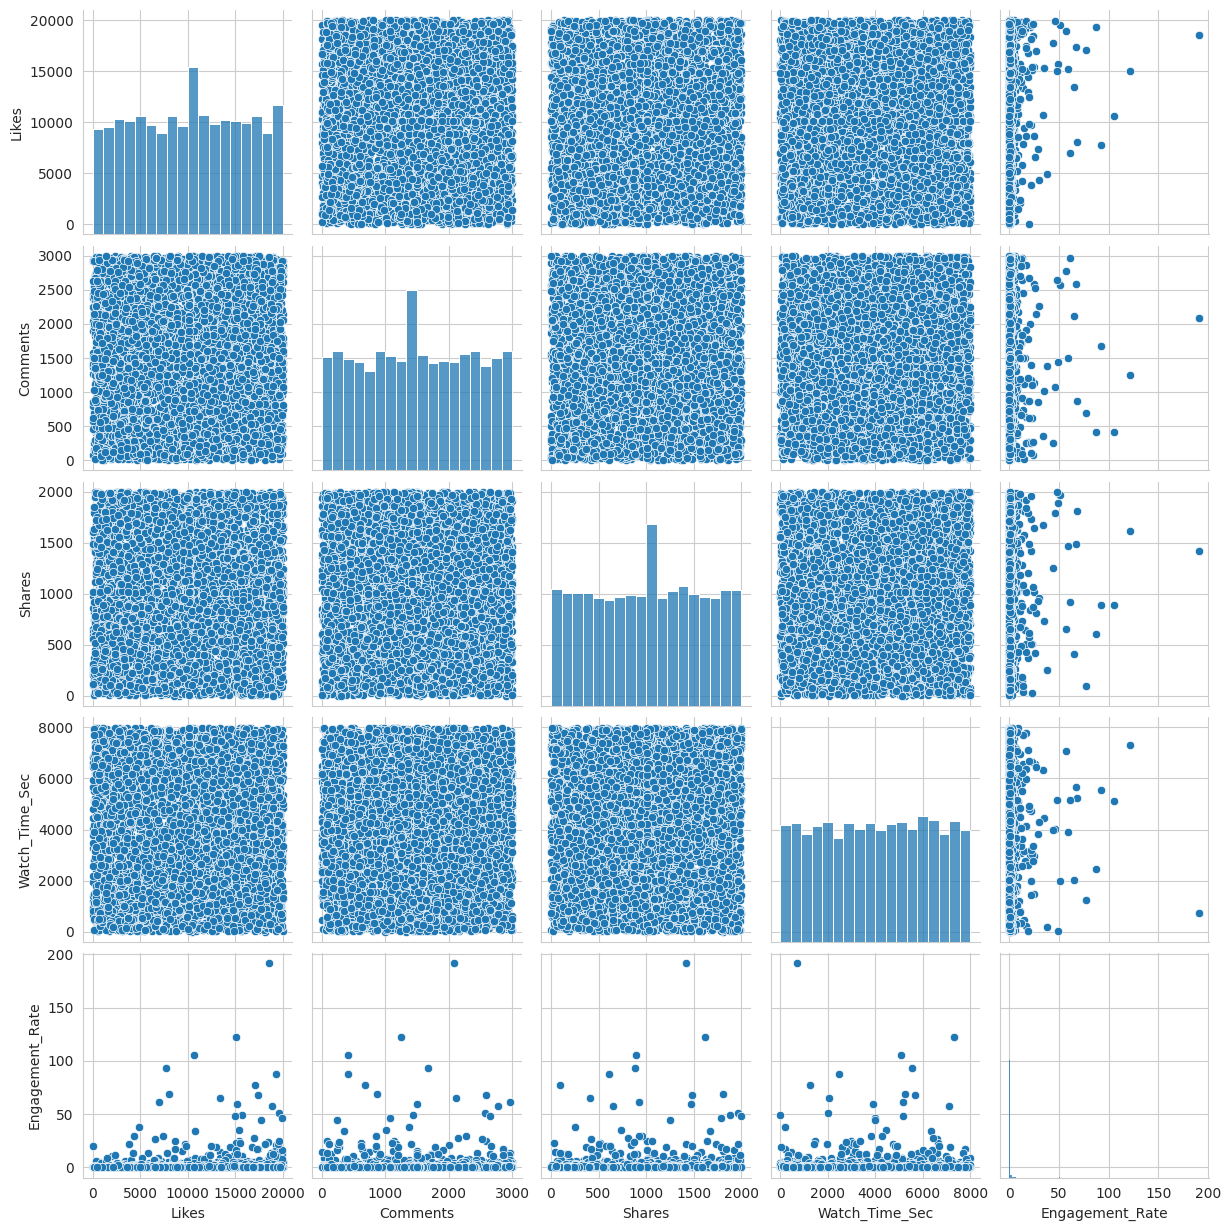

In [175]:
pairplot_data = df[
    ['Likes', 'Comments', 'Shares',
     'Watch_Time_Sec', 'Engagement_Rate']
].dropna()

sns.pairplot(pairplot_data)

plt.show()

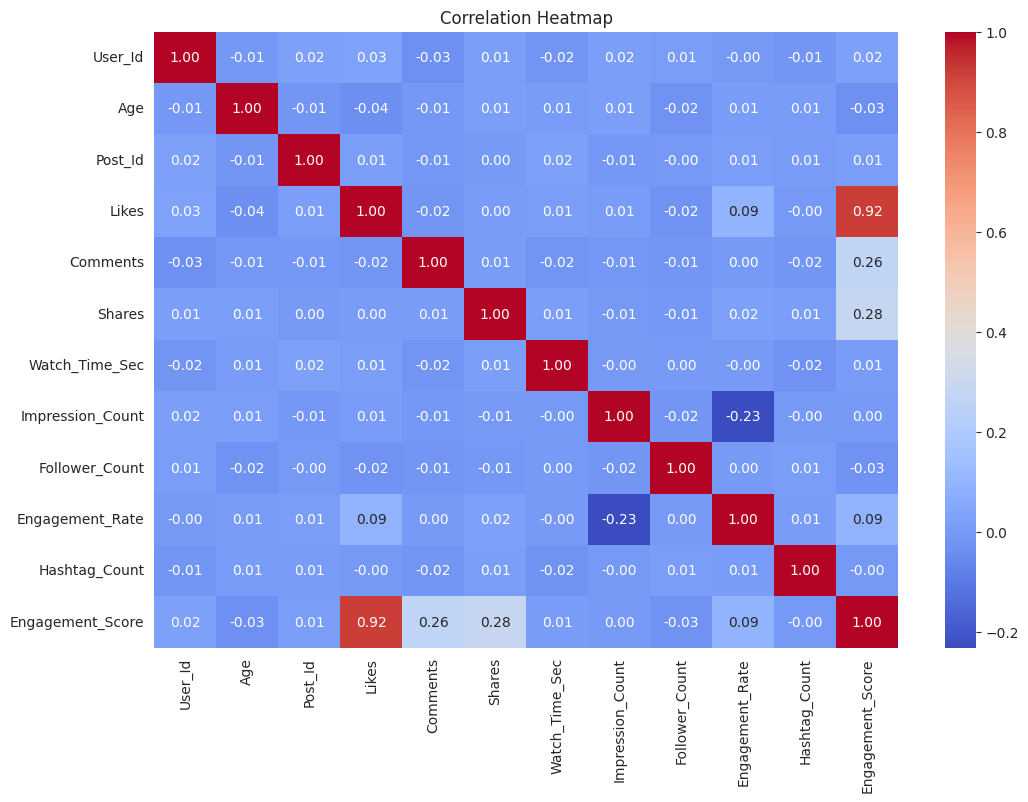

In [177]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 53.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 48.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 59.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 55.0% of the points cannot be plac

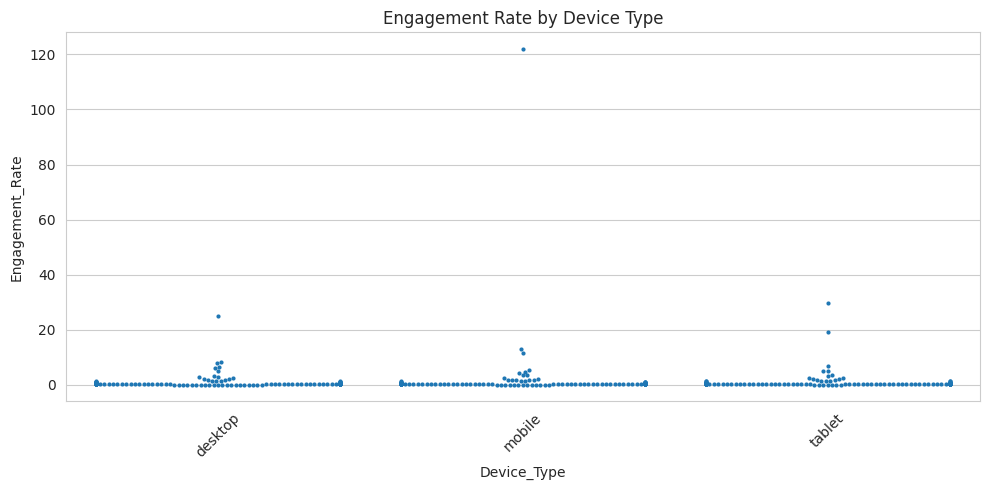

In [180]:
swarm_data = df.sample(
    n=min(500, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.swarmplot(
    data=swarm_data,
    x='Device_Type',
    y='Engagement_Rate',
    size=3
)

plt.title('Engagement Rate by Device Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [181]:
daily_df = df.copy()

daily_df['Posted_At'] = pd.to_datetime(
    daily_df['Posted_At'],
    errors='coerce',
    dayfirst=True
)

daily_summary = (
    daily_df.dropna(subset=['Posted_At'])
    .groupby(daily_df['Posted_At'].dt.date)['Engagement_Rate']
    .mean()
    .reset_index()
)

daily_summary.columns = ['date', 'average_engagement_rate']

fig = px.line(
    daily_summary,
    x='date',
    y='average_engagement_rate',
    title='Interactive Daily Engagement Trend',
    markers=True
)

fig.show()

In [183]:
category_summary = df.groupby(
    'Post_Category',
    observed=True
)['Likes'].mean().reset_index()

fig = px.bar(
    category_summary,
    x='Post_Category',
    y='Likes',
    title='Average Likes by Post Category',
    labels={
        'Post_Category': 'Post Category',
        'Likes': 'Average Likes'
    }
)

fig.show()

In [184]:
fig = px.scatter(
    df,
    x='Likes',
    y='Comments',
    size='Shares',
    color='Post_Type',
    hover_data=['Country', 'Sentiment'],
    title='Interactive Social Media Engagement Bubble Chart'
)

fig.show()

In [185]:
fig = px.scatter(
    df,
    x='Impression_Count',
    y='Likes',
    color='Post_Category',
    hover_data=['Post_Type', 'Country'],
    title='Interactive Impressions vs Likes'
)

fig.show()

In [186]:
content_performance = df.groupby(
    'Post_Type',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    average_comments=('Comments', 'mean'),
    average_shares=('Shares', 'mean')
).sort_values(
    by='average_engagement',
    ascending=False
)

content_performance

,average_engagement,average_likes,average_comments,average_shares
Post_Type,,,,
Video,1.122365,10188.600000,1479.160000,996.834286
Text,1.064549,10100.148193,1499.106024,1013.989558
Image,0.895646,10104.865277,1525.235766,1019.289495
Reel,0.783047,10037.802416,1504.187062,982.042089


In [190]:
category_performance = df.groupby(
    'Post_Category',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    total_posts=('Post_Id', 'count')
).sort_values(
    by='average_engagement',
    ascending=False
)

category_performance

,average_engagement,average_likes,total_posts
Post_Category,,,
Food,1.358628,10225.522766,593
Tech,1.160475,10171.571429,665
Lifestyle,1.091019,10180.559308,607
Music,0.888803,10205.749606,635
Fitness,0.865628,9914.602222,675
Education,0.844222,10126.487322,631
Fashion,0.807109,9843.356902,594
Travel,0.702223,10196.304167,600


In [191]:
country_performance = df.groupby(
    'Country',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    total_posts=('Post_Id', 'count'),
    average_likes=('Likes', 'mean')
).sort_values(
    by='average_engagement',
    ascending=False
)

country_performance.head(10)

,average_engagement,total_posts,average_likes
Country,,,
BRAZIL,1.540704,504,9886.689484
AUSTRALIA,1.324339,493,10294.124746
FRANCE,1.146402,496,10372.876008
UAE,1.112352,503,10227.487078
CANADA,0.916659,513,10063.066277
UK,0.850966,493,9935.650101
JAPAN,0.769623,472,10088.862288
GERMANY,0.759000,490,10130.458163
INDIA,0.655005,535,9962.468224


In [187]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=[
        'Under 18',
        '18-25',
        '26-35',
        '36-45',
        '46-60',
        'Above 60'
    ]
)

age_engagement = df.groupby(
    'Age_Group',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    total_posts=('Post_Id', 'count')
)

age_engagement

,average_engagement,average_likes,total_posts
Age_Group,,,
Under 18,0.867038,10495.145604,546
18-25,1.059536,10170.541925,644
26-35,0.865316,10240.393986,981
36-45,0.860741,10220.458643,1076
46-60,1.152669,9796.227601,1384
Above 60,0.801381,9901.868564,369


In [192]:
verified_performance = df.groupby(
    'Is_Verified',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    average_comments=('Comments', 'mean'),
    average_shares=('Shares', 'mean'),
    total_posts=('Post_Id', 'count')
)

verified_performance

,average_engagement,average_likes,average_comments,average_shares,total_posts
Is_Verified,,,,,
False,0.954744,10137.201129,1505.511401,1001.599292,4517
True,1.054250,9824.533126,1469.573499,1015.173913,483


In [188]:
df['Posted_At'] = pd.to_datetime(
    df['Posted_At'],
    errors='coerce',
    dayfirst=True
)

df['Post_Hour'] = df['Posted_At'].dt.hour

hourly_impressions = df.groupby(
    'Post_Hour'
).agg(
    average_impressions=('Impression_Count', 'mean'),
    total_impressions=('Impression_Count', 'sum'),
    total_posts=('Post_Id', 'count')
).sort_values(
    by='average_impressions',
    ascending=False
)

hourly_impressions

,average_impressions,total_impressions,total_posts
Post_Hour,,,
0,50013.7328,250068664,5000


In [189]:
best_hour = hourly_impressions['average_impressions'].idxmax()

print("Best posting hour:", best_hour)

Best posting hour: 0


In [194]:
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['Time_Period'] = df['Post_Hour'].apply(get_time_period)

time_performance = df.groupby(
    'Time_Period',
    observed=True
).agg(
    average_impressions=('Impression_Count', 'mean'),
    average_engagement=('Engagement_Rate', 'mean'),
    total_posts=('Post_Id', 'count')
).sort_values(
    by='average_impressions',
    ascending=False
)

time_performance

,average_impressions,average_engagement,total_posts
Time_Period,,,
Night,50013.7328,0.964356,5000


In [195]:
device_performance = df.groupby(
    'Device_Type',
    observed=True
).agg(
    average_watch_time=('Watch_Time_Sec', 'mean'),
    total_watch_time=('Watch_Time_Sec', 'sum'),
    average_engagement=('Engagement_Rate', 'mean'),
    total_posts=('Post_Id', 'count')
).sort_values(
    by='average_watch_time',
    ascending=False
)

device_performance

,average_watch_time,total_watch_time,average_engagement,total_posts
Device_Type,,,,
mobile,4087.830760,6883907,1.123999,1684
tablet,3979.736429,6598403,0.804560,1658
desktop,3974.792521,6590206,0.962006,1658


In [196]:
sentiment_performance = df.groupby(
    'Sentiment',
    observed=True
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    average_comments=('Comments', 'mean'),
    average_shares=('Shares', 'mean'),
    total_posts=('Post_Id', 'count')
).sort_values(
    by='average_engagement',
    ascending=False
)

sentiment_performance

,average_engagement,average_likes,average_comments,average_shares,total_posts
Sentiment,,,,,
Negative,1.038486,10208.096875,1516.094792,1007.307292,960
Neutral,0.991170,9923.194499,1528.404060,996.565160,1527
Positive,0.919744,10180.062077,1480.650617,1005.086749,2513


In [197]:
negative_neutral = df[
    df['Sentiment'].astype(str).str.strip().str.lower().isin(
        ['negative', 'neutral']
    )
]

negative_neutral_analysis = negative_neutral.groupby(
    negative_neutral['Sentiment'].astype(str).str.strip().str.title()
).agg(
    average_engagement=('Engagement_Rate', 'mean'),
    average_likes=('Likes', 'mean'),
    average_comments=('Comments', 'mean'),
    average_shares=('Shares', 'mean'),
    average_impressions=('Impression_Count', 'mean'),
    average_watch_time=('Watch_Time_Sec', 'mean'),
    total_posts=('Post_Id', 'count')
)

negative_neutral_analysis

,average_engagement,average_likes,average_comments,average_shares,average_impressions,average_watch_time,total_posts
Sentiment,,,,,,,
Negative,1.038486,10208.096875,1516.094792,1007.307292,50191.960417,4054.639583,960
Neutral,0.991170,9923.194499,1528.404060,996.565160,49515.971185,4031.823183,1527
